# Homework 7: Python Package
Kaiyi Wang - kw3297

## Part 1: Create the Package

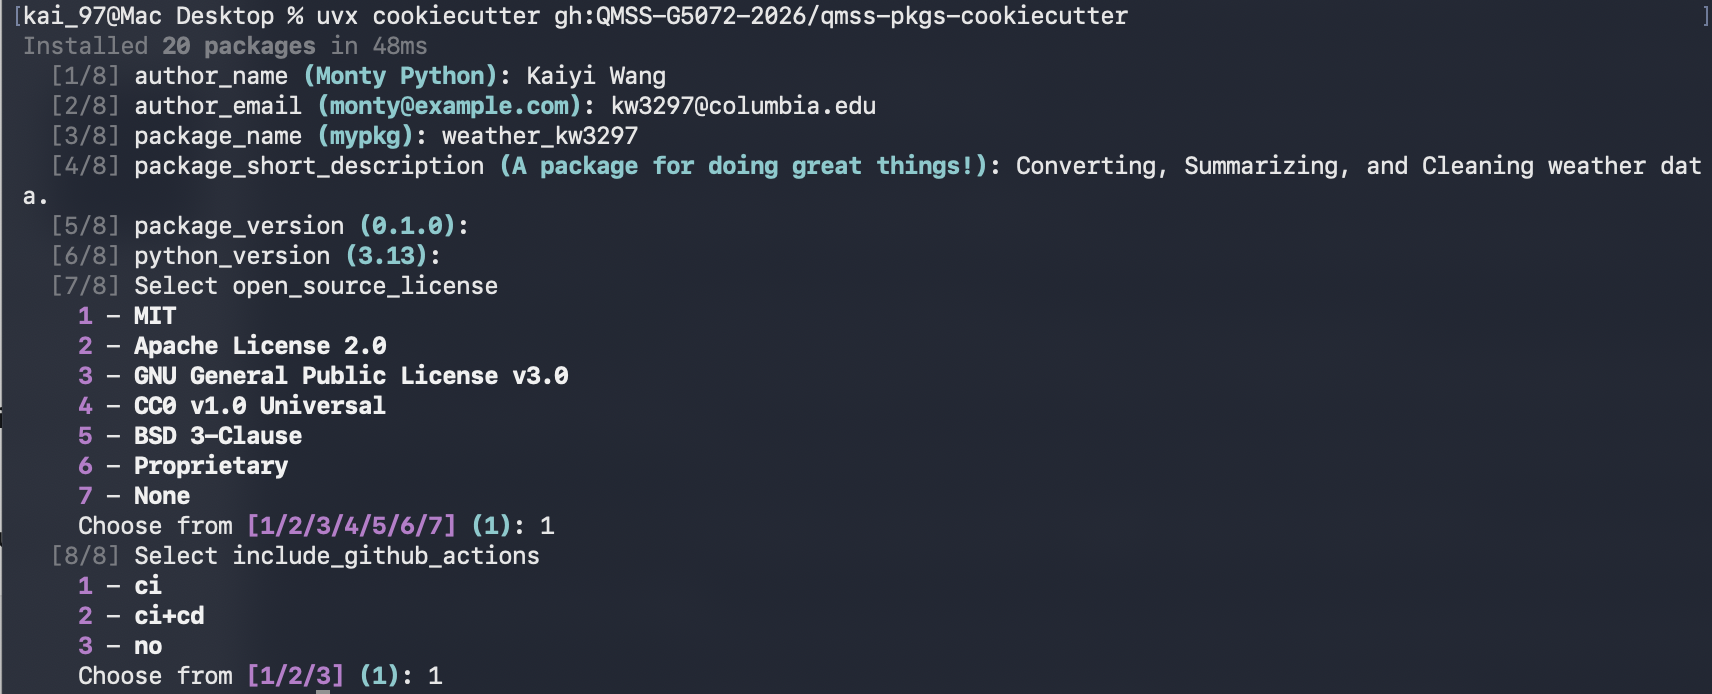

In [1]:
!cd "$HOME/Desktop/weather_kw3297" && uv sync

Using CPython 3.13.15
Creating virtual environment at: .venv
Resolved 83 packages in 341ms                                        
Prepared 35 packages in 686ms                                            
Installed 80 packages in 268ms                              
 + alabaster==1.0.0
 + appnope==1.0.0
 + astroid==4.3.4
 + asttokens==3.0.2
 + attrs==26.1.0
 + babel==2.18.0
 + certifi==2026.10.23
 + charset-normalizer==3.5.2
 + click==8.5.0
 + comm==0.2.3
 + coverage==7.17.2
 + debugpy==1.8.22
 + docutils==0.22.4
 + executing==2.3.0
 + fastjsonschema==2.22.3
 + idna==3.20
 + imagesize==2.0.1
 + importlib-metadata==10.1.0
 + iniconfig==2.3.1
 + ipykernel==7.4.0
 + ipython==9.18.1
 + ipython-pygments-lexers==1.1.1
 + jedi==0.20.1
 + jinja2==3.1.6
 + jsonschema==4.26.0
 + jsonschema-specifications==2025.9.1
 + jupyter-cache==1.0.1
 + jupyter-client==8.10.0
 + jupyter-core==5.9.1
 + markdown-it-py==4.2.0
 + markupsafe==3.0.4
 + matplotlib-inline==0.2.2
 + mdit-py-plugins==0.6.1
 + mdurl==0.

In [2]:
!cd "$HOME/Desktop/weather_kw3297" && ls -la

total 600
drwxr-xr-x   17 kai_97  staff     544 Nov  4 14:54 .
drwx------+ 173 kai_97  staff    5536 Nov  4 14:53 ..
drwxr-xr-x    3 kai_97  staff      96 Nov  4 14:50 .github
-rw-r--r--    1 kai_97  staff    1900 Nov  4 14:50 .gitignore
-rw-r--r--    1 kai_97  staff       5 Nov  4 14:50 .python-version
-rw-r--r--    1 kai_97  staff     391 Nov  4 14:50 .readthedocs.yml
drwxr-xr-x    9 kai_97  staff     288 Nov  4 14:54 .venv
-rw-r--r--    1 kai_97  staff     106 Nov  4 14:50 CHANGELOG.md
-rwxr-xr-x    1 kai_97  staff    3047 Nov  4 14:50 CONDUCT.md
-rwxr-xr-x    1 kai_97  staff    2373 Nov  4 14:50 CONTRIBUTING.md
drwxr-xr-x   10 kai_97  staff     320 Nov  4 14:50 docs
-rwxr-xr-x    1 kai_97  staff    1069 Nov  4 14:50 LICENSE
-rw-r--r--    1 kai_97  staff     738 Nov  4 14:50 pyproject.toml
-rw-r--r--    1 kai_97  staff    1130 Nov  4 14:50 README.md
drwxr-xr-x    3 kai_97  staff      96 Nov  4 14:50 src
drwxr-xr-x    3 kai_97  staff      96 Nov  4 14:50 tests
-rw-r--r--    1 kai_97 

Creating the environment (run uv sync) creates a .venv, which contains the project's Python environment; as well as uv.lock, which records the dependency versions. We only commit uv.lock so we can reproduce the environment.

In [3]:
!cd "$HOME/Desktop/weather_kw3297" && git remote -v

origin	https://github.com/QMSS-G5072-2026/weather_wang_kaiyi.git (fetch)
origin	https://github.com/QMSS-G5072-2026/weather_wang_kaiyi.git (push)


In [4]:
!cd "$HOME/Desktop/weather_kw3297" && git log --oneline

e31c8dd (HEAD -> main, origin/main) Initial package setup


https://github.com/QMSS-G5072-2026/weather_wang_kaiyi.git

## Part 2: Add Functions and their dependency

In [5]:
!cat "$HOME/Desktop/weather_kw3297/src/weather_kw3297/__init__.py"

# read version from installed package
from importlib.metadata import version
__version__ = version("weather_kw3297")

from .weather_kw3297 import (
    celsius_to_fahrenheit,
    summarize_temperatures,
    clean_readings,
)


In [6]:
!cd "$HOME/Desktop/weather_kw3297" && uv add pandas

Resolved 85 packages in 377ms                                        
Prepared 3 packages in 458ms                                             
Uninstalled 1 package in 1ms
Installed 3 packages in 18ms                                
 + numpy==2.5.4
 + pandas==3.1.1
 ~ weather-kw3297==0.1.0 (from file:///Users/kai_97/Desktop/weather_kw3297)


In [8]:
!cd "$HOME/Desktop/weather_kw3297" && uv run python -c "import weather_kw3297; print(weather_kw3297.celsius_to_fahrenheit(37))"

98.6


In [9]:
!cd "$HOME/Desktop/weather_kw3297" && uv run python -c "import weather_kw3297; print(weather_kw3297.summarize_temperatures([10.0, float('nan'), 20.0]))"

{'mean': 15.0, 'min': 10.0, 'max': 20.0, 'n_missing': 1}


In [10]:
!cd "$HOME/Desktop/weather_kw3297" && uv run python -c "import pandas as pd; import weather_kw3297; raw = pd.DataFrame({'station': ['JFK', 'CPK', 'JFK'], 'date': ['2026-07-02', '2026-07-01', '2026-07-01'], 'temp_c': [30.0, 25.0, float('nan')]}); print(weather_kw3297.clean_readings(raw))"

  station        date  temp_c  temp_f
0     CPK  2026-07-01    25.0    77.0
1     JFK  2026-07-02    30.0    86.0


In [11]:
!cd "$HOME/Desktop/weather_kw3297" && git diff -- pyproject.toml

diff --git a/pyproject.toml b/pyproject.toml
index ea2a557..30141b8 100644
--- a/pyproject.toml
+++ b/pyproject.toml
@@ -7,7 +7,9 @@ authors = [{ name = "Kaiyi Wang", email = "kw3297@columbia.edu" }]
 license = "MIT"
 license-files = ["LICENSE"]
 requires-python = ">=3.13"
-dependencies = []
+dependencies = [
+    "pandas>=3.1.1",
+]
 
 [dependency-groups]
 dev = [


In [12]:
!cd "$HOME/Desktop/weather_kw3297" && git status --short

 M pyproject.toml
 M src/weather_kw3297/__init__.py
 M src/weather_kw3297/weather_kw3297.py
 M uv.lock


uv add pandas changed pyproject.toml since pandas>=3.1.1 was added to the package dependencies, which also updated uv.lock to record the resolved dependency versions. The other two file change was due to my edit and not because of adding pandas.

In [13]:
!cd "$HOME/Desktop/weather_kw3297" && uv add --dev mypy pandas-stubs

Resolved 91 packages in 237ms                                        
Prepared 7 packages in 511ms                                             
Uninstalled 1 package in 1ms
Installed 7 packages in 14ms                                
 + ast-serialize==0.13.1
 + librt==0.16.0
 + mypy==2.4.1
 + mypy-extensions==1.2.0
 + pandas-stubs==3.1.0.261029
 + pathspec==1.1.1
 ~ weather-kw3297==0.1.0 (from file:///Users/kai_97/Desktop/weather_kw3297)


In [15]:
!cd "$HOME/Desktop/weather_kw3297" && uv run mypy src/weather_kw3297

Success: no issues found in 2 source files


# Part 3: Documentation

In [16]:
!cd "$HOME/Desktop/weather_kw3297" && uv run make -C docs html

Running Sphinx v9.2.0
loading translations [en]... done
making output directory... done
myst v5.1.0: MdParserConfig(commonmark_only=False, gfm_only=False, enable_extensions=set(), disable_syntax=[], all_links_external=False, links_external_new_tab=False, url_schemes=('http', 'https', 'mailto', 'ftp'), ref_domains=None, fence_as_directive=set(), number_code_blocks=[], title_to_header=False, heading_anchors=0, heading_slug_func=None, html_meta={}, footnote_sort=True, footnote_transition=True, words_per_minute=200, substitutions={}, linkify_fuzzy_links=True, dmath_allow_labels=True, dmath_allow_space=True, dmath_allow_digits=True, dmath_double_inline=False, update_mathjax=True, mathjax_classes='tex2jax_process|mathjax_process|math|output_area', enable_checkboxes=False, strikethrough_single_tilde=False, colon_fence_exact_match=False, suppress_warnings=[], highlight_code_blocks=True)
myst-nb v1.4.0: NbParserConfig(custom_formats={}, metadata_key='mystnb', cell_metadata_key='mystnb', kernel_

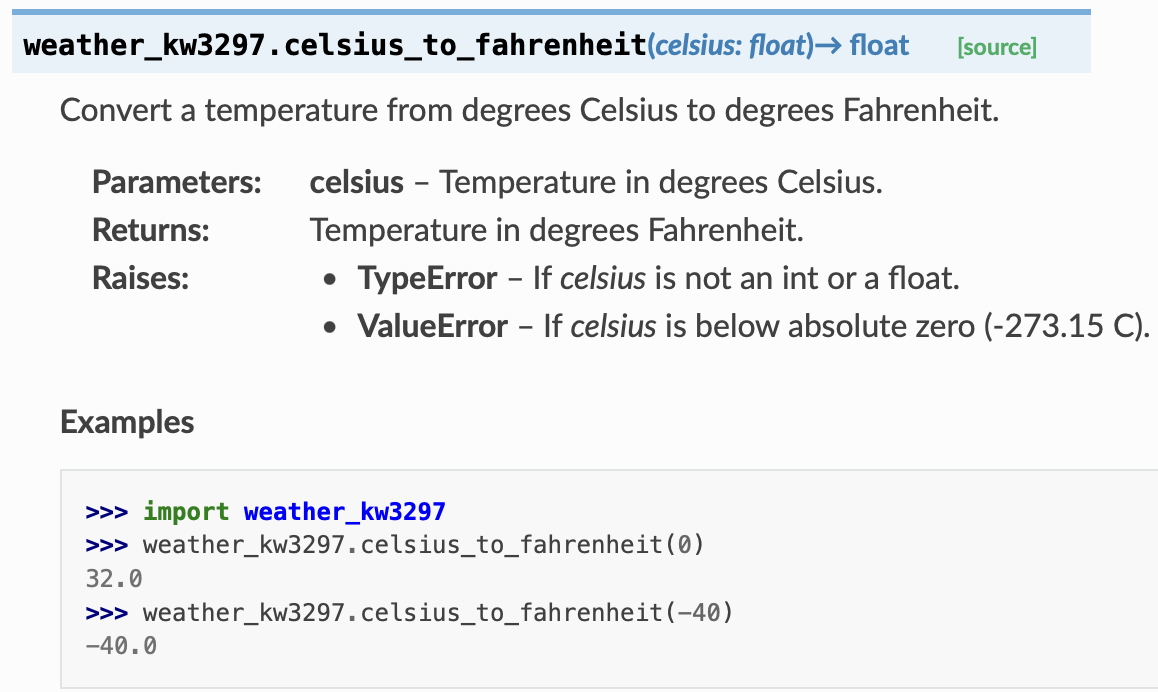

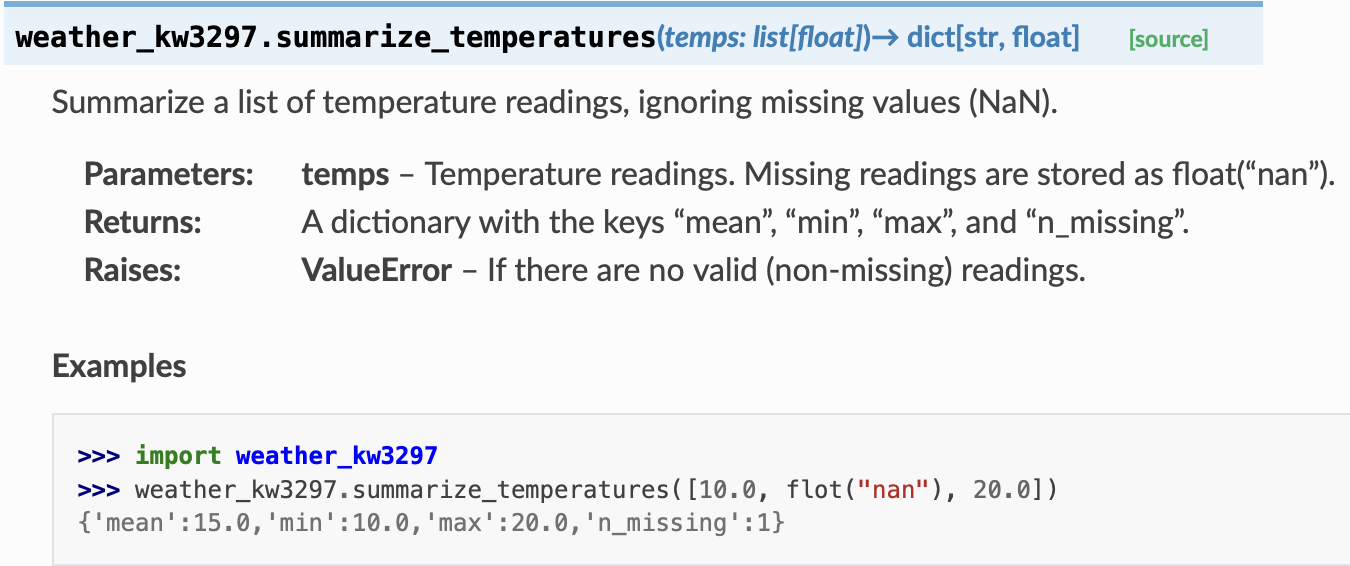

# Part 4: Tests, Coverage, and CI

In [17]:
!cd "$HOME/Desktop/weather_kw3297" && uv run pytest -vv --cov=weather_kw3297 --cov-report=term-missing --cov-report=html

============================= test session starts ==============================
platform darwin -- Python 3.13.15, pytest-9.2.0, pluggy-1.7.0 -- /Users/kai_97/Desktop/weather_kw3297/.venv/bin/python
cachedir: .pytest_cache
rootdir: /Users/kai_97/Desktop/weather_kw3297
configfile: pyproject.toml
plugins: platformdirs-4.14.5, cov-7.1.0
collected 12 items                                                             

tests/test_weather_kw3297.py::test_celsius_to_fahrenheit[0-32] PASSED    [  8%]
tests/test_weather_kw3297.py::test_celsius_to_fahrenheit[100-212] PASSED [ 16%]
tests/test_weather_kw3297.py::test_celsius_to_fahrenheit[-40--40] PASSED [ 25%]
tests/test_weather_kw3297.py::test_celsius_to_fahrenheit[37-98.6] PASSED [ 33%]
tests/test_weather_kw3297.py::test_celsius_to_fahrenheit[-273.15--459.67] PASSED [ 41%]
tests/test_weather_kw3297.py::test_celsius_to_fahrenheit_invalid[37-TypeError] PASSED [ 50%]
tests/test_weather_kw3297.py::test_celsius_to_fahrenheit_invalid[None-TypeError] 

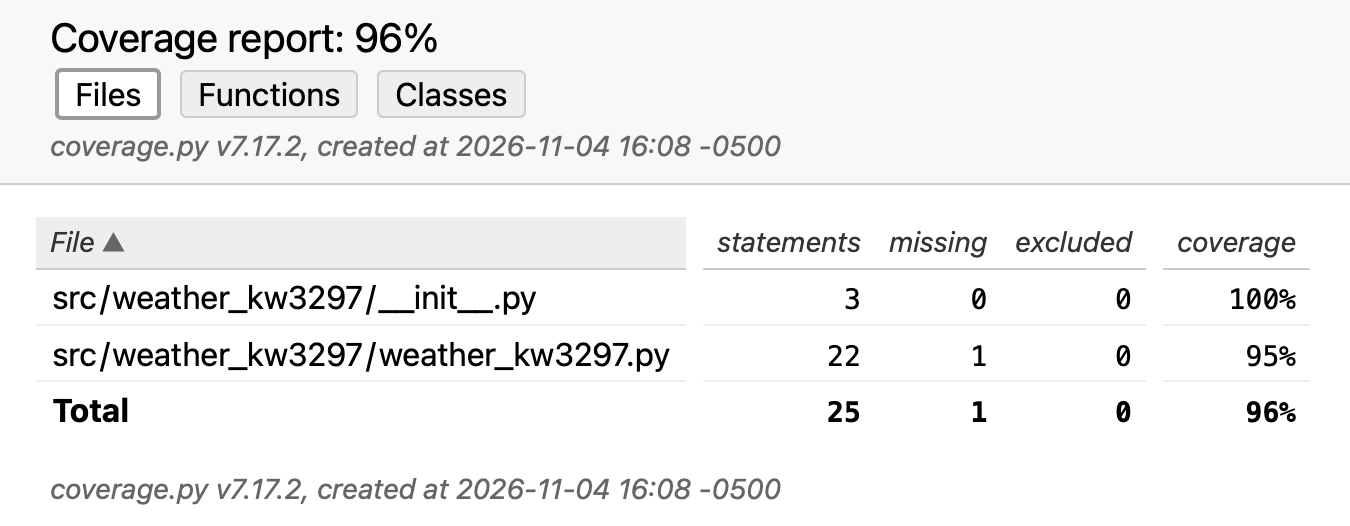

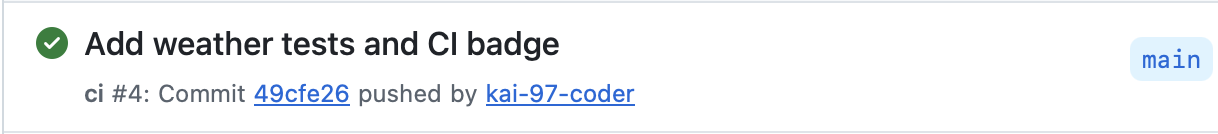

# Part 5: Build, Publish, and Install

In [18]:
!cd "$HOME/Desktop/weather_kw3297" && uv version --bump patch

Resolved 91 packages in 320ms                                        
Prepared 1 package in 347ms                                              
Uninstalled 1 package in 2ms
Installed 1 package in 37ms1 (from file:///Users/kai_97/Desk
 - weather-kw3297==0.1.0 (from file:///Users/kai_97/Desktop/weather_kw3297)
 + weather-kw3297==0.1.1 (from file:///Users/kai_97/Desktop/weather_kw3297)
weather-kw3297 0.1.0 => 0.1.1


In [19]:
!cd "$HOME/Desktop/weather_kw3297" && uv run pytest --cov=weather_kw3297

============================= test session starts ==============================
platform darwin -- Python 3.13.15, pytest-9.2.0, pluggy-1.7.0
rootdir: /Users/kai_97/Desktop/weather_kw3297
configfile: pyproject.toml
plugins: platformdirs-4.14.5, cov-7.1.0
collected 12 items                                                             

tests/test_weather_kw3297.py ............                                [100%]

================================ tests coverage ================================
______________ coverage: platform darwin, python 3.13.15-final-0 _______________

Name                                   Stmts   Miss  Cover
----------------------------------------------------------
src/weather_kw3297/__init__.py             3      0   100%
src/weather_kw3297/weather_kw3297.py      22      1    95%
----------------------------------------------------------
TOTAL                                     25      1    96%
============================== 12 passed in 0.37s ===============

In [20]:
!cd "$HOME/Desktop/weather_kw3297" && uv run mypy src/weather_kw3297

Success: no issues found in 2 source files


In [21]:
!cd "$HOME/Desktop/weather_kw3297" && uv lock --check

Resolved 91 packages in 3ms


In [22]:
!cd "$HOME/Desktop/weather_kw3297" && uv build

Building source distribution...
Successfully built dist/weather_kw3297-0.1.1.tar.gz
Successfully built dist/weather_kw3297-0.1.1-py3-none-any.whl


In [23]:
!cd "$HOME/Desktop/weather_kw3297" && ls -lh dist/

total 24
-rw-r--r--  1 kai_97  staff   4.2K Nov  4 16:19 weather_kw3297-0.1.1-py3-none-any.whl
-rw-r--r--  1 kai_97  staff   3.5K Nov  4 16:19 weather_kw3297-0.1.1.tar.gz


In [24]:
!cd "$HOME/Desktop/weather_kw3297" && uv run python -m zipfile -l dist/weather_kw3297-0.1.1-py3-none-any.whl

File Name                                             Modified             Size
weather_kw3297/                                1980-01-01 00:00:00            0
weather_kw3297/__init__.py                     1980-01-01 00:00:00          225
weather_kw3297/weather_kw3297.py               1980-01-01 00:00:00         2691
weather_kw3297-0.1.1.dist-info/licenses/       1980-01-01 00:00:00            0
weather_kw3297-0.1.1.dist-info/licenses/LICENSE 1980-01-01 00:00:00         1069
weather_kw3297-0.1.1.dist-info/                1980-01-01 00:00:00            0
weather_kw3297-0.1.1.dist-info/WHEEL           1980-01-01 00:00:00           80
weather_kw3297-0.1.1.dist-info/METADATA        1980-01-01 00:00:00         1552
weather_kw3297-0.1.1.dist-info/RECORD          1980-01-01 00:00:00          502


tests/, docs/, and github/ are missing. These folders support testing, documentation, and automated checks. Users do not need them to use functions. The wheel contains Python files and the metadata needed for installation.

In [25]:
!cd "$HOME/Desktop/QMSS 5072 HW1/HW7" && uv init --bare --no-workspace

Initialized project `hw7`


In [27]:
!cd "$HOME/Desktop/QMSS 5072 HW1/HW7" && uv add weather_kw3297

Using CPython 3.13.15
Creating virtual environment at: .venv
Resolved 6 packages in 737ms                                         
Prepared 1 package in 110ms                                              
Installed 5 packages in 59ms                                
 + numpy==2.5.4
 + pandas==3.1.1
 + python-dateutil==4.0.0
 + tzdata==2026.6
 + weather-kw3297==0.1.1


In [28]:
!cat "$HOME/Desktop/QMSS 5072 HW1/HW7/pyproject.toml"

[project]
name = "hw7"
version = "0.1.0"
requires-python = ">=3.13"
dependencies = [
    "weather-kw3297>=0.1.1",
]
[[tool.uv.index]]
name = "testpypi"
url = "https://test.pypi.org/simple/"
explicit = true

[tool.uv.sources]
weather_kw3297 = { index = "testpypi" }


In [29]:
!cd "$HOME/Desktop/QMSS 5072 HW1/HW7" && grep -A 3 -E '^name = "(weather-kw3297|pandas)"' uv.lock

name = "pandas"
version = "3.1.1"
source = { registry = "https://pypi.org/simple" }
dependencies = [
--
name = "weather-kw3297"
version = "0.1.1"
source = { registry = "https://test.pypi.org/simple/" }
dependencies = [


The lockfile shows that weather-kw3297 came from TestPyPI, and pandas came from PyPI.

## Part 6: Use installed Package

In [1]:
import weather_kw3297
import pandas as pd

print(weather_kw3297.__version__)
print(weather_kw3297.celsius_to_fahrenheit(37))
print(weather_kw3297.summarize_temperatures([10.0, float("nan"), 20.0]))

raw = pd.DataFrame({
    "station": ["JFK", "CPK", "JFK"],
    "date": ["2026-07-02", "2026-07-01", "2026-07-01"],
    "temp_c": [30.0, 25.0, float("nan")],
})
print(weather_kw3297.clean_readings(raw))

0.1.1
98.6
{'mean': 15.0, 'min': 10.0, 'max': 20.0, 'n_missing': 1}
  station        date  temp_c  temp_f
0     CPK  2026-07-01    25.0    77.0
1     JFK  2026-07-02    30.0    86.0


In [2]:
help(weather_kw3297.clean_readings)

Help on function clean_readings in module weather_kw3297.weather_kw3297:

clean_readings(df: pandas.DataFrame) -> pandas.DataFrame
    Clean raw station readings.

    Steps:
        1. Drop rows where `temp_c` is missing.
        2. Drop physically implausible readings (outside -90 C to 60 C, inclusive bounds are kept).
        3. Add a `temp_f` column with the temperature in Fahrenheit.
        4. Sort by `station`, then `date`, and reset the index.

    Args:
        df: DataFrame with the columns `station`, `date`, and `temp_c`.

    Returns:
        A new, cleaned DataFrame. The input DataFrame is not modified.



In [3]:
help(weather_kw3297.celsius_to_fahrenheit)

Help on function celsius_to_fahrenheit in module weather_kw3297.weather_kw3297:

celsius_to_fahrenheit(celsius: float) -> float
    Convert a temperature from degrees Celsius to degrees Fahrenheit.

    Args:
        celsius: Temperature in degrees Celsius.

    Returns:
        Temperature in degrees Fahrenheit.

    Raises:
        TypeError: If `celsius` is not an int or a float.
        ValueError: If `celsius` is below absolute zero (-273.15 C).

    Examples
    --------
    >>> import weather_kw3297
    >>> weather_kw3297.celsius_to_fahrenheit(0)
    32.0
    >>> weather_kw3297.celsius_to_fahrenheit(-40)
    -40.0



1 We commit uv.lock because it records the dependency versions used by the project, making it reproducible. The CI uses uv sync --locked, which requires an up-to-data lockfile; without it, that step fails.
2 Cookiecutter worked because uvx runs tools in a separate environment managed by uv. It can download things without adding them the the project.
3 We bumped the version to identify the release as 0.1.1 before building and publishing. TestPyPI will reject uploading the same distribution filenames again, so a changed release needs a new version.

### uv command log
uv run --no-project --with jupyter jupyter lab
uvx cookiecutter gh:QMSS-G5072-2026/qmss-pkgs-cookiecutter
uv sync
uv add pandas
uv run python -c "import weather_kw3297; print(weather_kw3297.celsius_to_fahrenheit(37))"
uv run python -c "import weather_kw3297; print(weather_kw3297.summarize_temperatures([10.0, float('nan'), 20.0]))"
uv run python -c "import pandas as pd; import weather_kw3297; raw = pd.DataFrame({'station': ['JFK', 'CPK', 'JFK'], 'date': ['2026-07-02', '2026-07-01', '2026-07-01'], 'temp_c': [30.0, 25.0, float('nan')]}); print(weather_kw3297.clean_readings(raw))"
uv add --dev mypy pandas-stubs
uv run mypy src/weather_kw3297
uv run make -C docs html
uv run pytest -vv --cov=weather_kw3297 --cov-report=term-missing --cov-report=html
uv version --bump patch
uv run pytest --cov=weather_kw3297
uv run mypy src/weather_kw3297
uv lock --check
uv build
uv run python -m zipfile -l dist/weather_kw3297-0.1.1-py3-none-any.whl
uv publish --index testpypi
uv init --bare --no-workspace
uv add weather_kw3297
uv run --with jupyter jupyter lab